In [74]:
import import_ipynb
import data_analysis

In [75]:
data_analysis.data

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Income_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,...,Education_Unknown,Income_Unknown,Marital_Unknown,Card_Category_Blue,Card_Category_Gold,Card_Category_Platinum,Card_Category_Silver,Marital_Divorced,Marital_Married,Marital_Single
0,0,45,0,3,1.0,2.0,39,5,1,3,...,0,0,0,True,False,False,False,False,True,False
1,0,49,1,5,3.0,0.0,44,6,1,2,...,0,0,0,True,False,False,False,False,False,True
2,0,51,0,3,3.0,3.0,36,4,1,0,...,0,0,0,True,False,False,False,False,True,False
3,0,40,1,4,1.0,0.0,34,3,4,1,...,0,0,1,True,False,False,False,False,True,False
4,0,40,0,3,0.0,2.0,21,5,1,0,...,0,0,0,True,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,0,50,0,2,3.0,1.0,40,3,2,3,...,0,0,0,True,False,False,False,False,False,True
10123,1,41,0,2,2.0,1.0,25,4,2,3,...,1,0,0,True,False,False,False,True,False,False
10124,1,44,1,1,1.0,0.0,36,5,3,4,...,0,0,0,True,False,False,False,False,True,False
10125,1,30,0,2,3.0,1.0,36,4,3,3,...,0,0,1,True,False,False,False,False,True,False


In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# Plain NumPy arrays, 1D labels (avoids Series/2D shape problems everywhere below)
X_train = np.asarray(data_analysis.X_scaled, dtype=float)
X_test  = np.asarray(data_analysis.X_test_scaled, dtype=float)
y_train = np.asarray(data_analysis.y_train).ravel().astype(int)
y_test  = np.asarray(data_analysis.y_test).ravel().astype(int)

print(X_train.shape, X_test.shape, "positive rate (train/test):", y_train.mean().round(3), y_test.mean().round(3))

(8101, 27) (2026, 27) positive rate (train/test): 0.161 0.16


In [77]:
rows = []   # one dict per model, filled by the cells below

def evaluate(name, y_true, y_pred, y_score=None):
    row = {
        "model": name,
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
    }
    rows[:] = [r for r in rows if r["model"] != name]
    rows.append(row)
    return row

# Baseline: always predict the majority class
majority = np.bincount(y_train).argmax()
evaluate("baseline (majority class)", y_test, np.full_like(y_test, majority), np.full(len(y_test), 0.5))
rows[-1]

{'model': 'baseline (majority class)',
 'accuracy': 0.8395853899308984,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'roc_auc': 0.5}

[BCE] Iteration 0, Cost: 0.69315
[BCE] Iteration 500, Cost: 0.24769
[BCE] Iteration 1000, Cost: 0.23717
[BCE] Iteration 1500, Cost: 0.23346
[MSE] Iteration 0, Cost: 0.25000
[MSE] Iteration 500, Cost: 0.07989
[MSE] Iteration 1000, Cost: 0.07449
[MSE] Iteration 1500, Cost: 0.07231
[MSE] Iteration 2000, Cost: 0.07108
[MSE] Iteration 2500, Cost: 0.07029
[MSE] Iteration 3000, Cost: 0.06974
[MSE] Iteration 3500, Cost: 0.06934
[MSE] Iteration 4000, Cost: 0.06905
[MSE] Iteration 4500, Cost: 0.06883


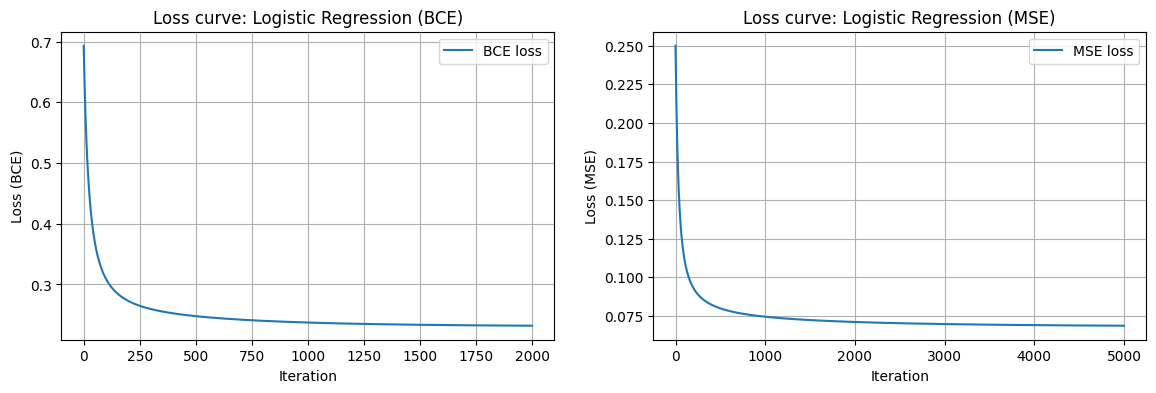

In [78]:
#Logistic regression select in rtype = MSE or BCE
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.1, num_iterations=2000, rtype='BCE', verbose=True):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.rtype = rtype
        self.verbose = verbose
        self.w = None
        self.b = None
        self.losses = []

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def _forward(self, X):                      # shape (n, 1)
        return self.sigmoid(X @ self.w + self.b)

    def predict_proba(self, X):                 # shape (n,)
        return self._forward(np.asarray(X, dtype=float)).ravel()

    def predict(self, X, threshold=0.5):        # shape (n,)
        return (self.predict_proba(X) >= threshold).astype(int)

    def cost_function(self, h, y):
        m = len(y)
        if self.rtype == "MSE":
            return np.sum((h - y) ** 2) / m
        elif self.rtype == "BCE":
            return -np.sum(y * np.log(h + 1e-8) + (1 - y) * np.log(1 - h + 1e-8)) / m
        raise ValueError("Invalid rtype. Use 'MSE' or 'BCE'.")

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        m, n_features = X.shape
        self.w = np.zeros((n_features, 1))
        self.b = 0.0
        self.losses = []

        for i in range(self.num_iterations):
            probs = self._forward(X)
            self.losses.append(self.cost_function(probs, y))

            if self.rtype == "MSE":
                dz = -2 * (y - probs) * probs * (1 - probs)
            else:  # BCE
                dz = probs - y

            self.w -= self.learning_rate * (X.T @ dz) / m
            self.b -= self.learning_rate * np.sum(dz) / m

            if self.verbose and i % 500 == 0:
                print(f"[{self.rtype}] Iteration {i}, Cost: {self.losses[-1]:.5f}")
        return self

    def plot_loss(self, ax=None):
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 5))
        ax.plot(self.losses, label=f'{self.rtype} loss')
        ax.set_xlabel("Iteration"); ax.set_ylabel(f"Loss ({self.rtype})")
        ax.set_title(f"Loss curve: Logistic Regression ({self.rtype})")
        ax.grid(True); ax.legend()
logreg_bce = LogisticRegressionScratch(learning_rate=0.1, num_iterations=2000, rtype='BCE').fit(X_train, y_train)
evaluate("LogReg scratch (BCE)", y_test, logreg_bce.predict(X_test), logreg_bce.predict_proba(X_test))

# MSE converges much more slowly, so give it the same learning rate and more iterations
logreg_mse = LogisticRegressionScratch(learning_rate=0.1, num_iterations=5000, rtype='MSE').fit(X_train, y_train)
evaluate("LogReg scratch (MSE)", y_test, logreg_mse.predict(X_test), logreg_mse.predict_proba(X_test))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
logreg_bce.plot_loss(axes[0]); logreg_mse.plot_loss(axes[1]); plt.show()   

In [79]:
#Decision tree
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, gain=None, value=None, proba=None):
        self.feature, self.threshold = feature, threshold
        self.left, self.right, self.gain = left, right, gain
        self.value, self.proba = value, proba          # set only on leaves


class DecisionTree:
    """Classifier with labels 0..K-1. Splits are exact: for each feature the data are sorted once and
    every boundary between distinct values is scored with cumulative class counts (no Python row loops)."""

    def __init__(self, min_samples=2, max_depth=5, min_gain=1e-7, max_features=None, random_state=None):
        self.max_features = max_features    # features tried per split (None = all); used by the random forest
        self.random_state = random_state
        self.min_samples = min_samples      # minimum samples needed to try a split
        self.max_depth = max_depth          # root is depth 0; nodes at max_depth become leaves
        self.min_gain = min_gain
        self.root = None

    @staticmethod
    def entropy(counts):
        """Entropy from class counts, shape (..., K)."""
        n = counts.sum(axis=-1, keepdims=True)
        p = counts / np.maximum(n, 1)
        plogp = np.where(p > 0, p * np.log2(np.where(p > 0, p, 1.0)), 0.0)
        return -plogp.sum(axis=-1)

    def best_split(self, X, y):
        n, d = X.shape
        total = np.bincount(y, minlength=self.K).astype(float)
        parent_entropy = self.entropy(total)
        best_feature, best_threshold, best_gain = None, None, 0.0
        onehot = np.eye(self.K)

        features = range(d) if not self.max_features else self.rng.choice(d, size=min(self.max_features, d), replace=False)
        for j in features:
            order = np.argsort(X[:, j], kind="stable")
            xs, ys = X[order, j], y[order]
            valid = np.nonzero(xs[:-1] < xs[1:])[0]          # split after position i, between distinct values
            if valid.size == 0:
                continue
            cum = np.cumsum(onehot[ys], axis=0)
            left = cum[valid]
            right = total - left
            n_left = valid + 1.0
            n_right = n - n_left
            gain = parent_entropy - (n_left * self.entropy(left) + n_right * self.entropy(right)) / n
            k = int(np.argmax(gain))
            if gain[k] > best_gain:
                best_feature, best_threshold, best_gain = j, xs[valid[k]], float(gain[k])   # rule: x <= threshold goes left
        return best_feature, best_threshold, best_gain

    def build_tree(self, X, y, depth=0):
        counts = np.bincount(y, minlength=self.K)
        leaf = Node(value=int(counts.argmax()), proba=counts / counts.sum())
        if len(y) < self.min_samples or depth >= self.max_depth or counts.max() == len(y):
            return leaf
        feature, threshold, gain = self.best_split(X, y)
        if feature is None or gain <= self.min_gain:
            return leaf
        mask = X[:, feature] <= threshold
        return Node(feature, threshold,
                    self.build_tree(X[mask], y[mask], depth + 1),
                    self.build_tree(X[~mask], y[~mask], depth + 1), gain)

    def fit(self, X, y, n_classes=None):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(int)     # accepts Series, 1D or (n,1) arrays
        self.K = int(n_classes) if n_classes else int(y.max()) + 1
        self.rng = np.random.default_rng(self.random_state)
        self.root = self.build_tree(X, y)
        return self

    def _route(self, X, idx, node, out):
        if node.value is not None:
            out[idx] = node.proba
            return
        go_left = X[idx, node.feature] <= node.threshold
        self._route(X, idx[go_left], node.left, out)
        self._route(X, idx[~go_left], node.right, out)

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        out = np.zeros((X.shape[0], self.K))
        self._route(X, np.arange(X.shape[0]), self.root, out)
        return out

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)
tree = DecisionTree(min_samples=2, max_depth=5).fit(X_train, y_train)
evaluate("Decision tree scratch (depth 5)", y_test, tree.predict(X_test), tree.predict_proba(X_test)[:, 1])
rows[-1]


{'model': 'Decision tree scratch (depth 5)',
 'accuracy': 0.9304047384007897,
 'precision': 0.7690058479532164,
 'recall': 0.8092307692307692,
 'f1': 0.7886056971514243,
 'roc_auc': 0.9596581196581196}

In [80]:
#Ensemble learning: Random Forest
class RandomForestClassifierFromScratch:
    """Bagged trees; each tree sees a bootstrap sample and every split considers a random subset of max_features features
    (drawn without replacement). Class probabilities are averaged across trees."""

    def __init__(self, max_feature=None, n_trees=100, min_sample_split=2, max_depth=10, random_state=42):
        self.n_estimators = n_trees
        self.max_features = max_feature
        self.min_sample_split = min_sample_split
        self.max_depth = max_depth
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(int)
        rng = np.random.default_rng(self.random_state)
        n, d = X.shape
        self.K = int(y.max()) + 1
        mf = self.max_features or int(round(np.sqrt(d)))
        self.trees = []
        for _ in range(self.n_estimators):
            rows_idx = rng.integers(0, n, size=n)                    # bootstrap sample
            tree = DecisionTree(self.min_sample_split, self.max_depth, max_features=mf,
                                random_state=int(rng.integers(0, 2**31 - 1)))
            tree.fit(X[rows_idx], y[rows_idx], n_classes=self.K)
            self.trees.append(tree)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        probs = np.zeros((X.shape[0], self.K))
        for tree in self.trees:
            probs += tree.predict_proba(X)
        return probs / self.n_estimators

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)
rf = RandomForestClassifierFromScratch(n_trees=100, max_depth=10, random_state=42).fit(X_train, y_train)   # max_features = sqrt(25) = 5
evaluate("Random forest scratch", y_test, rf.predict(X_test), rf.predict_proba(X_test)[:, 1])
rows[-1]

{'model': 'Random forest scratch',
 'accuracy': 0.9491609081934848,
 'precision': 0.937007874015748,
 'recall': 0.7323076923076923,
 'f1': 0.8221070811744386,
 'roc_auc': 0.9854149143038031}

In [81]:
#Ensemble learning: Stacking classifiers, Gradient Boosting (GB), Extreme-Gradient Boosting (XGBoost)
class GBMClassifier:
    """Multiclass gradient boosting with softmax loss. Each round fits one regression tree per class to the
    negative gradient (y - p); the tree's own leaf means are used as the update, and the same update is used
    in fit() and predict(). logitboost=True uses the K-class LogitBoost working response with sample weights."""

    def __init__(self, logitboost=False, learning_rate=0.1, n_estimators=100, max_depth=3, random_state=0):
        self.logitboost = logitboost
        self.learning_rate = learning_rate
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.random_state = random_state

    @staticmethod
    def _softmax(z):
        z = z - z.max(axis=1, keepdims=True)
        e = np.exp(z)
        return e / e.sum(axis=1, keepdims=True)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(int)
        self.K = int(y.max()) + 1
        Y = np.eye(self.K)[y]
        self.trees = {k: [] for k in range(self.K)}
        F = np.zeros((len(y), self.K))

        for _ in range(self.n_estimators):
            P = self._softmax(F)                      # same probabilities for all classes in this round
            for k in range(self.K):
                if self.logitboost:
                    w = np.clip(P[:, k] * (1 - P[:, k]), 1e-6, None)
                    r = np.clip((self.K - 1) / self.K * (Y[:, k] - P[:, k]) / w, -4, 4)
                else:
                    w, r = None, Y[:, k] - P[:, k]
                tree = DecisionTreeRegressor(criterion='friedman_mse', max_depth=self.max_depth,
                                             random_state=self.random_state)
                tree.fit(X, r, sample_weight=w)
                self.trees[k].append(tree)
                F[:, k] += self.learning_rate * tree.predict(X)
        return self

    def decision_function(self, X):
        X = np.asarray(X, dtype=float)
        F = np.zeros((X.shape[0], self.K))
        for k in range(self.K):
            for tree in self.trees[k]:
                F[:, k] += self.learning_rate * tree.predict(X)
        return F

    def predict_proba(self, X):
        return self._softmax(self.decision_function(X))

    def predict(self, X):
        return self.decision_function(X).argmax(axis=1)

gbc = GBMClassifier(learning_rate=0.1, n_estimators=100, max_depth=3, random_state=0).fit(X_train, y_train)
evaluate("Gradient boosting scratch", y_test, gbc.predict(X_test), gbc.predict_proba(X_test)[:, 1])
rows[-1]

{'model': 'Gradient boosting scratch',
 'accuracy': 0.9466929911154985,
 'precision': 0.9322709163346613,
 'recall': 0.72,
 'f1': 0.8125,
 'roc_auc': 0.9767747478858589}

In [82]:
#Naïve Bayes Classification (from “Discrete Mathematics” course; if any)
class NaiveBayes:
    """Gaussian Naive Bayes with variance smoothing (same idea as scikit-learn's var_smoothing)."""

    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel()
        self.classes = np.unique(y)
        self.mean = np.array([X[y == c].mean(axis=0) for c in self.classes])
        self.variance = np.array([X[y == c].var(axis=0) for c in self.classes])
        self.variance += self.var_smoothing * X.var(axis=0).max()      # avoids division by zero
        self.priors = np.array([(y == c).mean() for c in self.classes])
        return self

    def log_posterior(self, X):
        X = np.asarray(X, dtype=float)
        out = []
        for i in range(len(self.classes)):
            log_pdf = -0.5 * np.log(2 * np.pi * self.variance[i]) - (X - self.mean[i]) ** 2 / (2 * self.variance[i])
            out.append(np.log(self.priors[i]) + log_pdf.sum(axis=1))
        return np.column_stack(out)

    def predict_proba(self, X):
        lp = self.log_posterior(X)
        lp -= lp.max(axis=1, keepdims=True)
        p = np.exp(lp)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes[self.log_posterior(X).argmax(axis=1)]
nb = NaiveBayes().fit(X_train, y_train)
evaluate("Naive Bayes scratch", y_test, nb.predict(X_test), nb.predict_proba(X_test)[:, 1])
rows[-1]  

{'model': 'Naive Bayes scratch',
 'accuracy': 0.8761105626850938,
 'precision': 0.6267123287671232,
 'recall': 0.563076923076923,
 'f1': 0.593192868719611,
 'roc_auc': 0.8369158413602857}

In [83]:
#Support vector machine
class SVMScratch:
    """Linear soft-margin SVM เรียนด้วย subgradient descent บน hinge loss
    objective: (1/(2C))*||w||^2 + mean(sample_weight * hinge)
    class_weight='balanced' ถ่วงน้ำหนักแต่ละคลาสด้วย n / (2 * n_class)
    label {0,1} ถูกแปลงเป็น {-1,+1} ภายใน decision_function คือ margin ที่มีเครื่องหมาย
    predict_proba บีบ margin ผ่าน sigmoid เพื่อให้ใช้กับ evaluate เดิมและวัด ROC-AUC ได้
    ค่านี้ไม่ใช่ความน่าจะเป็นจริง ใช้เรียงลำดับเท่านั้น"""
    
    def __init__(self, C=1000.0, learning_rate=0.1, num_iterations=3000,
                 class_weight=None, verbose=False):
        self.C = C
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.class_weight = class_weight
        self.verbose = verbose
        self.w = None
        self.b = 0.0
        self.losses = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(int)
        y_pm = np.where(y == 1, 1.0, -1.0)
        m, n = X.shape

        sw = np.ones(m)
        if self.class_weight == "balanced":
            for c in (0, 1):
                sw[y == c] = m / (2.0 * (y == c).sum())

        self.w = np.zeros(n)
        self.b = 0.0
        self.losses = []

        for t in range(1, self.num_iterations + 1):
            margins = y_pm * (X @ self.w + self.b)
            viol = margins < 1                          # จุดที่ละเมิด margin
            coef = sw * viol * y_pm
            grad_w = self.w / self.C - (X * coef[:, None]).sum(axis=0) / m
            grad_b = -coef.sum() / m
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b

            loss = 0.5 * (self.w @ self.w) / self.C + np.mean(sw * np.maximum(0, 1 - margins))
            self.losses.append(loss)
            if self.verbose and t % 500 == 0:
                print(f"[SVM] iter {t}, loss {loss:.5f}")
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict_proba(self, X):
        z = np.clip(self.decision_function(X), -500, 500)
        return 1 / (1 + np.exp(-z))

    def predict(self, X):
        return (self.decision_function(X) >= 0).astype(int)

    def plot_loss(self, ax=None, title="Loss curve: SVM (scratch)"):
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 5))
        ax.plot(self.losses)
        ax.set_xlabel("Iteration"); ax.set_ylabel("Hinge loss + L2 term")
        ax.set_title(title); ax.grid(True)

svm = SVMScratch().fit(X_train, y_train)
evaluate("SVM scratch (linear)", y_test, svm.predict(X_test), svm.predict_proba(X_test))
rows[-1]

{'model': 'SVM scratch (linear)',
 'accuracy': 0.8993089832181639,
 'precision': 0.7894736842105263,
 'recall': 0.5076923076923077,
 'f1': 0.6179775280898876,
 'roc_auc': 0.9061511328177995}

In [84]:
#Dimensionality reduction for random forest / support vector machine (feature selection)
class MutualInfoSelector:
    """Filter-based feature selection: จัดอันดับ feature ด้วย mutual information กับ y แล้วเก็บ top-k
    MI(X;Y) = sum p(x,y) * log( p(x,y) / (p(x) p(y)) ) คำนวณจากตารางความถี่
    feature ต่อเนื่องถูกแบ่งเป็น n_bins ช่วงตาม quantile ส่วน feature ที่มีค่าไม่ซ้ำน้อย ใช้ค่าตรงๆ"""

    def __init__(self, k=10, n_bins=10):
        self.k = k
        self.n_bins = n_bins

    def _discretize(self, x):
        if len(np.unique(x)) <= self.n_bins:
            return np.unique(x, return_inverse=True)[1]
        edges = np.quantile(x, np.linspace(0, 1, self.n_bins + 1)[1:-1])
        return np.searchsorted(np.unique(edges), x)

    def _mutual_info(self, x, y):
        xd = self._discretize(x)
        joint = np.zeros((xd.max() + 1, 2))
        np.add.at(joint, (xd, y), 1)
        pxy = joint / joint.sum()
        px = pxy.sum(axis=1, keepdims=True)
        py = pxy.sum(axis=0, keepdims=True)
        mask = pxy > 0
        return float((pxy[mask] * np.log(pxy[mask] / (px @ py)[mask])).sum())

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(int)
        self.scores_ = np.array([self._mutual_info(X[:, j], y) for j in range(X.shape[1])])
        self.ranking_ = np.argsort(self.scores_)[::-1]
        self.selected_ = np.sort(self.ranking_[:self.k])      # เก็บลำดับคอลัมน์เดิมไว้
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.selected_]

feature_names = list(X_train.columns) if hasattr(X_train, "columns") else [f"x{i}" for i in range(X_train.shape[1])]
selector = MutualInfoSelector(k=10).fit(X_train, y_train)
X_train_sel = selector.transform(X_train)
X_test_sel = selector.transform(X_test)
{"features_before": X_train.shape[1], "features_kept": X_train_sel.shape[1],
 "selected": [(feature_names[j], round(float(selector.scores_[j]), 4)) for j in selector.ranking_[:selector.k]]}

{'features_before': 27,
 'features_kept': 10,
 'selected': [('x14', 0.1013),
  ('x13', 0.0977),
  ('x10', 0.0714),
  ('x15', 0.0671),
  ('x16', 0.0471),
  ('x8', 0.0269),
  ('x7', 0.0245),
  ('x12', 0.0172),
  ('x6', 0.0145),
  ('x11', 0.0112)]}

In [85]:
# Random forest บน feature ที่เลือกด้วย mutual information (hyperparameter เดียวกับ RF เดิม)
rf_sel = RandomForestClassifierFromScratch(n_trees=100, max_depth=10, random_state=42).fit(X_train_sel, y_train)
evaluate("Random forest scratch + feature selection", y_test, rf_sel.predict(X_test_sel), rf_sel.predict_proba(X_test_sel)[:, 1])
rows[-1]

{'model': 'Random forest scratch + feature selection',
 'accuracy': 0.9536031589338598,
 'precision': 0.8969072164948454,
 'recall': 0.803076923076923,
 'f1': 0.8474025974025974,
 'roc_auc': 0.9850893139782028}

In [86]:
# SVM บน feature ที่เลือกด้วย mutual information
svm_sel = SVMScratch().fit(X_train_sel, y_train)
evaluate("SVM scratch + feature selection", y_test, svm_sel.predict(X_test_sel), svm_sel.predict_proba(X_test_sel))
rows[-1]

{'model': 'SVM scratch + feature selection',
 'accuracy': 0.8958538993089832,
 'precision': 0.7794117647058824,
 'recall': 0.48923076923076925,
 'f1': 0.6011342155009451,
 'roc_auc': 0.9056862479084702}

In [87]:
# SVM แบบ balanced บน feature ที่เลือกด้วย mutual information
svm_sel_bal = SVMScratch(class_weight="balanced").fit(X_train_sel, y_train)
evaluate("SVM scratch + feature selection (balanced)", y_test, svm_sel_bal.predict(X_test_sel), svm_sel_bal.predict_proba(X_test_sel))
rows[-1]

{'model': 'SVM scratch + feature selection (balanced)',
 'accuracy': 0.8440276406712734,
 'precision': 0.5085714285714286,
 'recall': 0.8215384615384616,
 'f1': 0.6282352941176471,
 'roc_auc': 0.9185745941301497}

In [88]:
#Supervised clustering: k-Nearest Neighbors
class KNNClassifier:
    """Brute-force kNN: เก็บ training set ไว้ทั้งหมด ทำนายด้วยการโหวตของ k จุดที่ใกล้ที่สุด ระยะ Euclidean
    weighted=True ถ่วงเสียงโหวตด้วย 1/ระยะ ให้จุดใกล้มีผลมากกว่า
    class_weight="balanced" คูณเสียงโหวตของแต่ละคลาสด้วย n / (2 * n_class)
    predict_proba คือสัดส่วนเสียงโหวตของแต่ละคลาส ใช้กับ evaluate เพื่อวัด ROC-AUC"""

    def __init__(self, k=15, weighted=False, class_weight=None):
        self.k = k
        self.weighted = weighted
        self.class_weight = class_weight

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y).ravel().astype(int)
        self.K = int(self.y_train.max()) + 1
        counts = np.bincount(self.y_train, minlength=self.K)
        self.cw = (len(self.y_train) / (self.K * counts) if self.class_weight == "balanced"
                   else np.ones(self.K))
        return self

    def _neighbors(self, X):
        # ระยะกำลังสองทุกคู่ด้วย (a-b)^2 = a^2 + b^2 - 2ab ไม่ต้องวนลูปทีละแถว
        dists = ((X ** 2).sum(axis=1, keepdims=True)
                 + (self.X_train ** 2).sum(axis=1)[None, :]
                 - 2 * X @ self.X_train.T)
        k = min(self.k, len(self.X_train))
        idx = np.argpartition(dists, k - 1, axis=1)[:, :k]
        return idx, np.take_along_axis(dists, idx, axis=1)

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        idx, dists = self._neighbors(X)
        neighbor_labels = self.y_train[idx]                       # (n, k)
        w = 1 / np.sqrt(np.maximum(dists, 1e-12)) if self.weighted else np.ones_like(dists)
        out = np.zeros((X.shape[0], self.K))
        for c in range(self.K):
            out[:, c] = self.cw[c] * (w * (neighbor_labels == c)).sum(axis=1)
        return out / out.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

# เลือก k จาก validation ที่แบ่งจาก train เท่านั้น ไม่แตะ test
# ไม่ลอง k=1 เพราะจะจำ noise ของ train ทุกจุดและ ROC-AUC ใช้ไม่ได้ เพราะมีแค่ 2 ค่าของคะแนน
_Xtr, _ytr = np.asarray(X_train, dtype=float), np.asarray(y_train)
_perm = np.random.default_rng(42).permutation(len(_Xtr))
_n_val = int(0.2 * len(_Xtr))
_val, _fit = _perm[:_n_val], _perm[_n_val:]

knn_val_f1 = {}
for k in [3, 5, 7, 11, 15, 21, 31, 51]:
    m = KNNClassifier(k=k).fit(_Xtr[_fit], _ytr[_fit])
    knn_val_f1[k] = f1_score(_ytr[_val], m.predict(_Xtr[_val]), zero_division=0)
best_k = max(knn_val_f1, key=knn_val_f1.get)

# เทรนบน train ทั้งหมดด้วย k ที่ดีที่สุด แล้ววัดบน test
knn = KNNClassifier(k=best_k).fit(X_train, y_train)
evaluate(f"kNN scratch (k={best_k})", y_test, knn.predict(X_test), knn.predict_proba(X_test)[:, 1])
rows[-1]

{'model': 'kNN scratch (k=3)',
 'accuracy': 0.8854886475814413,
 'precision': 0.7384615384615385,
 'recall': 0.4430769230769231,
 'f1': 0.5538461538461539,
 'roc_auc': 0.8293827160493826}

In [89]:
#Unsupervised clustering: k-Means
class KMeansScratch:
    """Lloyd's algorithm + k-means++ initialization, รัน n_init รอบแล้วเก็บรอบที่ inertia ต่ำสุด"""

    def __init__(self, n_clusters=2, max_iter=300, n_init=10, random_state=0):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.n_init = n_init
        self.random_state = random_state

    def _sqdist(self, X, centers):
        return (X ** 2).sum(axis=1, keepdims=True) + (centers ** 2).sum(axis=1)[None, :] - 2 * X @ centers.T

    def _kmeanspp_init(self, X, rng):
        n = len(X)
        centers = [X[rng.integers(n)]]
        d2 = ((X - centers[0]) ** 2).sum(axis=1)
        for _ in range(1, self.n_clusters):
            centers.append(X[rng.choice(n, p=d2 / d2.sum())])
            d2 = np.minimum(d2, ((X - centers[-1]) ** 2).sum(axis=1))
        return np.array(centers)

    def _run_once(self, X, rng):
        centers = self._kmeanspp_init(X, rng)
        for _ in range(self.max_iter):
            labels = self._sqdist(X, centers).argmin(axis=1)
            new_centers = np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else centers[k]
                                    for k in range(self.n_clusters)])
            if np.allclose(new_centers, centers):
                break
            centers = new_centers
        labels = self._sqdist(X, centers).argmin(axis=1)
        return centers, labels, ((X - centers[labels]) ** 2).sum()

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        rng = np.random.default_rng(self.random_state)
        best = None
        for _ in range(self.n_init):
            result = self._run_once(X, rng)
            if best is None or result[2] < best[2]:
                best = result
        self.cluster_centers_, self.labels_, self.inertia_ = best
        return self

    def predict(self, X):
        return self._sqdist(np.asarray(X, dtype=float), self.cluster_centers_).argmin(axis=1)


def cluster_positive_rate(cluster_labels, y, n_clusters):
    """สัดส่วน y=1 ในแต่ละ cluster ของ train  cluster ว่างใช้สัดส่วนรวมแทน"""
    rate = np.full(n_clusters, np.mean(y))
    for k in range(n_clusters):
        mask = cluster_labels == k
        if mask.any():
            rate[k] = y[mask].mean()
    return rate

_ytr = np.asarray(y_train)
_perm = np.random.default_rng(42).permutation(len(X_train_sel))
_n_val = int(0.2 * len(X_train_sel))
_val, _fit = _perm[:_n_val], _perm[_n_val:]

km2_val = {}
for n_clusters in [5, 10, 20, 40, 80]:
    m = KMeansScratch(n_clusters=n_clusters, n_init=3, random_state=42).fit(X_train_sel[_fit])
    rate = cluster_positive_rate(m.labels_, _ytr[_fit], n_clusters)
    score_val = rate[m.predict(X_train_sel[_val])]
    for thr in [0.2, 0.3, 0.4, 0.5]:                       # cluster ที่มีสัดส่วน churn >= thr ถูกทำนายเป็น churn
        km2_val[(n_clusters, thr)] = f1_score(_ytr[_val], (score_val >= thr).astype(int), zero_division=0)
best_nc2, best_thr2 = max(km2_val, key=km2_val.get)

km2 = KMeansScratch(n_clusters=best_nc2, n_init=10, random_state=42).fit(X_train_sel)
km2_rate = cluster_positive_rate(km2.labels_, _ytr, best_nc2)
km2_score = km2_rate[km2.predict(X_test_sel)]
evaluate(f"k-Means scratch (k={best_nc2}, thr={best_thr2})",
         y_test, (km2_score >= best_thr2).astype(int), km2_score)
rows[-1]

{'model': 'k-Means scratch (k=80, thr=0.4)',
 'accuracy': 0.8835143139190523,
 'precision': 0.6246498599439776,
 'recall': 0.6861538461538461,
 'f1': 0.6539589442815249,
 'roc_auc': 0.8834567901234569}

In [90]:
#Unsupervised clustering: agglomerative clustering
# ต้องรัน cell k-Means ก่อน เพราะใช้ cluster_positive_rate ร่วมกัน
class AgglomerativeScratch:
    """Bottom-up hierarchical clustering แบบ average linkage  เริ่มจากทุกจุดเป็น cluster เดี่ยว
    แล้วรวม 2 cluster ที่ใกล้กันที่สุดทีละคู่จนเหลือ n_clusters  ระยะใหม่คำนวณด้วย Lance-Williams
    d(a+b, c) = (n_a * d(a,c) + n_b * d(b,c)) / (n_a + n_b) ซึ่งเท่ากับค่าเฉลี่ยระยะทุกคู่
    ใช้ distance matrix เต็ม n x n จึงกินเวลาและหน่วยความจำ n^2 ไม่เหมาะกับ train ทั้งก้อน
    predict จุดใหม่ด้วยระยะเฉลี่ยไปยังสมาชิกของแต่ละ cluster ซึ่งสอดคล้องกับ average linkage"""

    def __init__(self, n_clusters=2):
        self.n_clusters = n_clusters

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.X_ = X
        n = len(X)
        sq = (X ** 2).sum(axis=1)
        D = np.sqrt(np.maximum(sq[:, None] + sq[None, :] - 2 * X @ X.T, 0))
        np.fill_diagonal(D, np.inf)
        size = np.ones(n)
        members = {i: [i] for i in range(n)}
        active = np.ones(n, dtype=bool)

        for _ in range(n - self.n_clusters):
            a, b = np.unravel_index(np.argmin(D), D.shape)
            new = (size[a] * D[a] + size[b] * D[b]) / (size[a] + size[b])
            D[a, :] = new
            D[:, a] = new
            D[a, a] = np.inf
            D[b, :] = np.inf
            D[:, b] = np.inf
            size[a] += size[b]
            members[a].extend(members.pop(b))
            active[b] = False

        self.labels_ = np.empty(n, dtype=int)
        for new_id, idx in enumerate(members.values()):
            self.labels_[idx] = new_id
        self.n_clusters_ = len(members)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        sq_x, sq_t = (X ** 2).sum(axis=1), (self.X_ ** 2).sum(axis=1)
        D = np.sqrt(np.maximum(sq_x[:, None] + sq_t[None, :] - 2 * X @ self.X_.T, 0))   # (n_new, n_fit)
        onehot = np.eye(self.n_clusters_)[self.labels_]                                   # (n_fit, k)
        mean_dist = (D @ onehot) / onehot.sum(axis=0)
        return mean_dist.argmin(axis=1)

_ytr = np.asarray(y_train)
_sub = np.random.default_rng(42).choice(len(X_train_sel), size=min(2000, len(X_train_sel)), replace=False)
_fit, _val = _sub[:1500], _sub[1500:]

agg2_val = {}
for n_clusters in [5, 10, 20, 40]:
    m = AgglomerativeScratch(n_clusters=n_clusters).fit(X_train_sel[_fit])
    rate = cluster_positive_rate(m.labels_, _ytr[_fit], m.n_clusters_)
    score_val = rate[m.predict(X_train_sel[_val])]
    for thr in [0.2, 0.3, 0.4, 0.5]:
        agg2_val[(n_clusters, thr)] = f1_score(_ytr[_val], (score_val >= thr).astype(int), zero_division=0)
best_nc_agg2, best_thr_agg2 = max(agg2_val, key=agg2_val.get)

agg2 = AgglomerativeScratch(n_clusters=best_nc_agg2).fit(X_train_sel[_sub])
agg2_rate = cluster_positive_rate(agg2.labels_, _ytr[_sub], agg2.n_clusters_)
agg2_score = agg2_rate[agg2.predict(X_test_sel)]
evaluate(f"Agglomerative scratch (k={best_nc_agg2}, thr={best_thr_agg2})",
         y_test, (agg2_score >= best_thr_agg2).astype(int), agg2_score)
rows[-1]

{'model': 'Agglomerative scratch (k=10, thr=0.2)',
 'accuracy': 0.8524185587364265,
 'precision': 0.8421052631578947,
 'recall': 0.09846153846153846,
 'f1': 0.1763085399449036,
 'roc_auc': 0.6003147469814136}

In [94]:
#Perceptron & Single-layer perceptron (SLP)
class PerceptronScratch:
    """Rosenblatt perceptron: นิวรอนเดียว ฟังก์ชัน step  อัปเดตน้ำหนักเฉพาะตอนทำนายผิด ไม่มี gradient
    w <- w + lr * y * x,  b <- b + lr * y   เมื่อ y * (w.x + b) <= 0  โดย label {0,1} แปลงเป็น {-1,+1}
    ข้อมูลที่แยกด้วยเส้นตรงไม่ได้ น้ำหนักจะแกว่งไม่ลู่เข้า จึงใช้ averaged=True เฉลี่ยน้ำหนักทุกก้าว
    class_weight="balanced" คูณขนาดการอัปเดตด้วย n / (2 * n_class)
    หมายเหตุ: เริ่มจาก w=0 ค่า learning_rate แค่ย่อหรือขยายน้ำหนักทั้งหมด ไม่เปลี่ยนคำทำนาย"""

    def __init__(self, learning_rate=0.1, num_iterations=50, averaged=True,
                 class_weight=None, random_state=42):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.averaged = averaged
        self.class_weight = class_weight
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(int)
        y_pm = np.where(y == 1, 1.0, -1.0)
        m, n = X.shape
        sw = np.ones(m)
        if self.class_weight == "balanced":
            for c in (0, 1):
                sw[y == c] = m / (2.0 * (y == c).sum())

        rng = np.random.default_rng(self.random_state)
        w, b = np.zeros(n), 0.0
        w_sum, b_sum, steps = np.zeros(n), 0.0, 0
        self.mistakes_ = []
        for epoch in range(self.num_iterations):
            mistakes = 0
            for i in rng.permutation(m):                    # สลับลำดับข้อมูลทุก epoch
                if y_pm[i] * (X[i] @ w + b) <= 0:
                    step = self.learning_rate * sw[i] * y_pm[i]
                    w += step * X[i]
                    b += step
                    mistakes += 1
                w_sum += w; b_sum += b; steps += 1
            self.mistakes_.append(mistakes)
            if mistakes == 0:                               # แยกข้อมูล train ได้หมดแล้ว
                break
        self.w, self.b = (w_sum / steps, b_sum / steps) if self.averaged else (w, b)
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w + self.b

    def predict(self, X):
        return (self.decision_function(X) >= 0).astype(int)

    def predict_proba(self, X):
        # perceptron ไม่มีความน่าจะเป็นในตัว ใช้ sigmoid ของ margin เพื่อเรียงลำดับสำหรับ ROC-AUC เท่านั้น
        z = np.clip(self.decision_function(X), -500, 500)
        return 1 / (1 + np.exp(-z))

    def plot_mistakes(self, ax=None, title="Perceptron: training mistakes per epoch"):
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 5))
        ax.plot(self.mistakes_)
        ax.set_xlabel("Epoch"); ax.set_ylabel("Mistakes")
        ax.set_title(title); ax.grid(True)

perc = PerceptronScratch().fit(X_train, y_train)
evaluate("Perceptron scratch", y_test, perc.predict(X_test), perc.predict_proba(X_test))
rows[-1]

{'model': 'Perceptron scratch',
 'accuracy': 0.8968410661401777,
 'precision': 0.7589285714285714,
 'recall': 0.5230769230769231,
 'f1': 0.6193078324225865,
 'roc_auc': 0.903200832089721}

In [95]:
class SLPScratch:
    """Single-layer perceptron: ชั้นเดียว นิวรอนเอาต์พุตเดียว activation เป็น sigmoid  p = sigmoid(w.x + b)
    ต่างจาก perceptron ตรงที่ output ต่อเนื่องและเรียนด้วย gradient descent บน binary cross-entropy
    gradient ต่อน้ำหนักคือ mean( sw * (p - y) * x )  full-batch
    class_weight="balanced" ถ่วงน้ำหนักแต่ละตัวอย่างด้วย n / (2 * n_class)"""

    def __init__(self, learning_rate=0.5, num_iterations=3000, class_weight=None, verbose=False):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.class_weight = class_weight
        self.verbose = verbose

    @staticmethod
    def _sigmoid(z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).ravel().astype(float)
        m, n = X.shape
        sw = np.ones(m)
        if self.class_weight == "balanced":
            for c in (0, 1):
                sw[y == c] = m / (2.0 * (y == c).sum())

        self.w, self.b = np.zeros(n), 0.0
        self.losses = []
        eps = 1e-12
        for t in range(1, self.num_iterations + 1):
            p = self._sigmoid(X @ self.w + self.b)
            err = sw * (p - y)
            self.w -= self.learning_rate * (X.T @ err) / m
            self.b -= self.learning_rate * err.mean()
            loss = -np.mean(sw * (y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
            self.losses.append(loss)
            if self.verbose and t % 500 == 0:
                print(f"[SLP] iter {t}, loss {loss:.5f}")
        return self

    def predict_proba(self, X):
        return self._sigmoid(np.asarray(X, dtype=float) @ self.w + self.b)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

    def plot_loss(self, ax=None, title="Loss curve: SLP (scratch)"):
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 5))
        ax.plot(self.losses)
        ax.set_xlabel("Iteration"); ax.set_ylabel("Binary cross-entropy")
        ax.set_title(title); ax.grid(True)

slp = SLPScratch().fit(X_train, y_train)
evaluate("SLP scratch", y_test, slp.predict(X_test), slp.predict_proba(X_test))
rows[-1]

{'model': 'SLP scratch',
 'accuracy': 0.9012833168805529,
 'precision': 0.7802690582959642,
 'recall': 0.5353846153846153,
 'f1': 0.635036496350365,
 'roc_auc': 0.9157635779858001}

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Random forest scratch + feature selection,0.9536,0.8969,0.8031,0.8474,0.9851
Random forest scratch,0.9492,0.9370,0.7323,0.8221,0.9854
Gradient boosting scratch,0.9467,0.9323,0.7200,0.8125,0.9768
Decision tree scratch (depth 5),0.9304,0.7690,0.8092,0.7886,0.9597
"k-Means scratch (k=80, thr=0.4)",0.8835,0.6246,0.6862,0.6540,0.8835
"SLP scratch (sigmoid, BCE)",0.9013,0.7803,0.5354,0.6350,0.9158
SLP scratch,0.9013,0.7803,0.5354,0.6350,0.9158
LogReg scratch (MSE),0.9013,0.7907,0.5231,0.6296,0.9050
SVM scratch + feature selection (balanced),0.8440,0.5086,0.8215,0.6282,0.9186


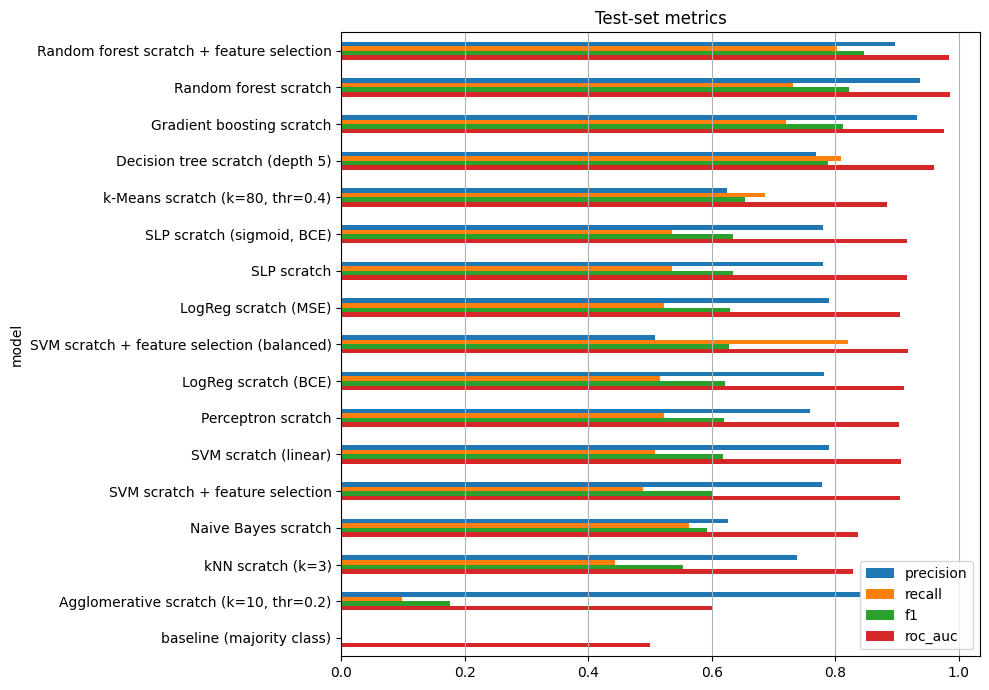

In [96]:
results = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False)
display(results.round(4))

ax = results[["precision", "recall", "f1", "roc_auc"]].plot.barh(figsize=(10, 7))
ax.set_title("Test-set metrics"); ax.invert_yaxis(); ax.grid(axis="x"); plt.tight_layout(); plt.show()